In [1]:
import importlib
import rotation_dataset
from torchvision.models import resnet18, ResNet18_Weights


importlib.reload(rotation_dataset)

print(rotation_dataset.__file__)
print(dir(rotation_dataset))

/home/hannes-karlsson/Chalmers/courses/DeepMachineLearning/Project/notebooks/rotation_dataset.py
['Dataset', 'Path', 'RotatedCDnetDataset', '__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__spec__', 'calculate_zoom', 'csv', 'cv2', 'generate_angles', 'hashlib', 'np', 're', 'rotate_images']


In [72]:
from rotation_dataset import RotatedCDnetDataset

In [73]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from rotation_dataset import RotatedCDnetDataset

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

Device: cpu


In [74]:
DATA_FOLDER = Path("data") / "Single Object trajectory"

PROJECT_ROOT = next(
    (
        p for p in [Path.cwd(), *Path.cwd().parents]
        if (p / DATA_FOLDER).is_dir()
    ),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not find project directory")

DATA_ROOT = PROJECT_ROOT / DATA_FOLDER

print("Project:", PROJECT_ROOT)
print("Data:", DATA_ROOT)

Project: /home/hannes-karlsson/Chalmers/courses/DeepMachineLearning/Project
Data: /home/hannes-karlsson/Chalmers/courses/DeepMachineLearning/Project/data/Single Object trajectory


In [116]:
train_dataset = RotatedCDnetDataset(
    dataset_id="Person3_CNNGRU_train_90deg_v2",
    video_dir=DATA_ROOT / "train" / "Person1",
    mode="train",
    seed=40,
    max_angle=90,
    max_step=10,
    log_root=PROJECT_ROOT / "Logs"
)

val_dataset = RotatedCDnetDataset(
    dataset_id="Person2_CNNGRU_val_90deg_v2",
    video_dir=DATA_ROOT / "val" / "Person2",
    mode="fixed",
    seed=40,
    max_angle=90,
    max_step=10,
    log_root=PROJECT_ROOT / "Logs"
)

print("Training frames:", train_dataset.num_frames)
print("Validation frames:", val_dataset.num_frames)

Training frames: 103
Validation frames: 113


In [117]:
class RotationCNNGRU(nn.Module):

    def __init__(self, hidden_size=128):
        super().__init__()

        # CNN: compare current frame with reference frame
        # 6 input channels = 3 RGB + 3 RGB

        backbone = resnet18(
            weights = ResNet18_Weights.DEFAULT
        )

        self.encoder = nn.Sequential(
            *list(backbone.children())[:-2]
        )
        for param in self.encoder.parameters():
            param.requires_grad=False # Freeze layers

        self.spatial_pool = nn.AdaptiveAvgPool2d((2, 3)) # ?

        feature_dim = 512 * 2 * 3 # How did we decide this

        self.projection = nn.Sequential(
            nn.Linear(feature_dim * 2, 128),
            nn.ReLU(),
            nn.Dropout(0.1)
        )

        """
        self.encoder = nn.Sequential(

            nn.Conv2d(6, 32, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),

            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),

            nn.Conv2d(64, 128, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),

            nn.AdaptiveAvgPool2d((2, 2)),
            nn.Flatten()
        )
        """

        # GRU: model rotation over time
        self.gru = nn.GRU(
            input_size=128,
            hidden_size=hidden_size,
            batch_first=True
        )

        # Output: cosine and sine of rotation angle
        self.head = nn.Linear(hidden_size, 2)

        self.register_buffer(
            "mean",
            torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
        )

        self.register_buffer(
            "std",
            torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
        )

    def forward(self, frames, reference, hidden=None):
        # frames: [T, 3, H, W]
        # reference: [3, H, W]

        T = frames.shape[0]

        self.encoder.eval()

        frames = (frames - self.mean) / self.std # normalization

        reference = reference.unsqueeze(0)
        reference = (reference - self.mean) / self.std

        reference_features = self.encoder(reference)
        frame_features = self.encoder(frames)

        reference_features = self.spatial_pool(
            reference_features
        ).flatten(1)

        frame_features = self.spatial_pool(
            frame_features
        ).flatten(1)

        # Compare current frame with reference frame
        reference_features = reference_features.expand(T, -1)

        difference = frame_features - reference_features

        combined = torch.cat(
            [frame_features, difference],
            dim=1
        )

        features = self.projection(combined)

        # Process chronological sequence
        features = features.unsqueeze(0)

        output, hidden = self.gru(
            features,
            hidden
        )

        predictions = self.head(
            output.squeeze(0)
        )

        predictions = F.normalize(
            predictions,
            dim=-1,
            eps=1e-6
        )

        return predictions, hidden

In [119]:
"""
torch.manual_seed(42)


model = RotationCNNGRU(
    hidden_size=128
).to(device)

print(model)


torch.manual_seed(42)

model = RotationCNNGRU(
    hidden_size=128
).to(device)

optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=0.0003,
    weight_decay=1e-4
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(f"Trainable parameters: {trainable_params:,}")

"""

# Initialize the same model architecture
model = RotationCNNGRU(
    hidden_size=128
).to(device)

# Path to your saved model
checkpoint_path = (
    PROJECT_ROOT
    / "models"
    / f"resnet18_gru_Person1_CNNGRU_train_90deg_v1.pth"
)


# Load the checkpoint
checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

# Restore the trained weights
model.load_state_dict(
    checkpoint["model_state_dict"]
)

print("Loaded model from epoch:", checkpoint["epoch"] + 1)
print("Previous validation loss:", checkpoint["val_loss"])

Loaded model from epoch: 28
Previous validation loss: 0.0018990581454368964


In [120]:
dummy_frames = torch.randn(
    16, 3, 96, 128,
    device=device
)

dummy_reference = torch.randn(
    3, 96, 128,
    device=device
)

with torch.no_grad():

    predictions, hidden = model(
        dummy_frames,
        dummy_reference
    )

print("Predictions:", predictions.shape)
print("Hidden state:", hidden.shape)

Predictions: torch.Size([16, 2])
Hidden state: torch.Size([1, 1, 128])


In [121]:
def prepare_frames(frames, device, image_size):

    # NumPy: [T, H, W, 3]
    # PyTorch: [T, 3, H, W]

    images = torch.from_numpy(
        np.ascontiguousarray(frames)
    ).to(device)

    images = images.permute(0, 3, 1, 2)
    images = images.float() / 255.0

    # BGR -> RGB
    images = images[:, [2, 1, 0], :, :]

    images = F.interpolate(
        images,
        size=image_size,
        mode="bilinear",
        align_corners=False
    )

    return images

In [122]:
def rotation_loss(predictions, true_angles):

    radians = torch.deg2rad(true_angles)

    targets = torch.stack(
        [
            torch.cos(radians),
            torch.sin(radians)
        ],
        dim=-1
    )

    similarity = (
        predictions * targets
    ).sum(dim=-1)

    return (1 - similarity).mean()

In [123]:
def run_video(
    dataset,
    model,
    device,
    optimizer=None,
    chunk_size=16,
    max_image_side=128
):

    training = optimizer is not None

    model.train(training)

    # Load one complete video
    sample = dataset[0]

    frames = sample["rotated_frames"]
    angles = sample["angles_deg"]

    num_frames = len(frames)

    # Calculate a smaller image size while preserving aspect ratio
    height, width = frames.shape[1:3]

    scale = max_image_side / max(height, width)

    image_size = (
        max(8, round(height * scale / 8) * 8),
        max(8, round(width * scale / 8) * 8)
    )

    # First frame is the reference
    reference = prepare_frames(
        frames[:1],
        device,
        image_size
    )[0]

    # New hidden state at the start of each video
    hidden = None

    total_loss = 0.0
    all_predictions = []

    with torch.set_grad_enabled(training):

        for start in range(0, num_frames, chunk_size):

            end = min(start + chunk_size, num_frames)

            # Load current chunk onto GPU
            images = prepare_frames(
                frames[start:end],
                device,
                image_size
            )

            # True rotation angles
            true_angles = torch.as_tensor(
                angles[start:end],
                dtype=torch.float32,
                device=device
            )

            # Forward pass
            predictions, hidden = model(
                images,
                reference,
                hidden
            )

            loss = rotation_loss(
                predictions,
                true_angles
            )

            if training:

                optimizer.zero_grad(set_to_none=True)

                loss.backward()

                # Stabilize GRU training
                nn.utils.clip_grad_norm_(
                    model.parameters(),
                    max_norm=1.0
                )

                optimizer.step()

            # Keep the hidden state, but stop gradient history
            hidden = hidden.detach()

            total_loss += loss.item() * (end - start)

            if not training:
                all_predictions.append(
                    predictions.detach().cpu()
                )

    average_loss = total_loss / num_frames

    if training:
        return average_loss, None, angles

    all_predictions = torch.cat(
        all_predictions,
        dim=0
    ).numpy()

    return average_loss, all_predictions, angles

In [124]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

num_epochs = 30
chunk_size = 16

train_losses = []
val_losses = []

best_val_loss = float("inf")

model_dir = PROJECT_ROOT / "models"
model_dir.mkdir(parents=True, exist_ok=True)

checkpoint_path = (
    PROJECT_ROOT
    / "models"
    / f"resnet18_gru_{train_dataset.dataset_id}.pth"
)

In [125]:
for epoch in range(num_epochs):

    # Generate a new continuous training trajectory
    train_dataset.set_epoch(epoch)

    # Train on the complete training video
    train_loss, _, _ = run_video(
        dataset=train_dataset,
        model=model,
        device=device,
        optimizer=optimizer,
        chunk_size=chunk_size,
        max_image_side=192
    )

    # Validate on a fixed, complete video
    val_loss, _, _ = run_video(
        dataset=val_dataset,
        model=model,
        device=device,
        optimizer=optimizer,
        chunk_size=chunk_size,
        max_image_side=192
    )
    

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    print(
        f"Epoch {epoch + 1}/{num_epochs} | "
        f"Train loss: {train_loss:.4f} | "
        f"Val loss: {val_loss:.4f}"
    )

    # Save the best model
    if val_loss < best_val_loss:

        best_val_loss = val_loss

        torch.save(
            {
                "model_state_dict": model.state_dict(),
                "epoch": epoch,
                "train_dataset_id": train_dataset.dataset_id,
                "val_dataset_id": val_dataset.dataset_id,
                "val_loss": val_loss
            },
            checkpoint_path
        )

print("Training complete!")

Epoch 1/30 | Train loss: 0.0108 | Val loss: 0.0068
Epoch 2/30 | Train loss: 0.0089 | Val loss: 0.0051
Epoch 3/30 | Train loss: 0.0161 | Val loss: 0.0039
Epoch 4/30 | Train loss: 0.0073 | Val loss: 0.0125
Epoch 5/30 | Train loss: 0.0085 | Val loss: 0.0039
Epoch 6/30 | Train loss: 0.0121 | Val loss: 0.0024
Epoch 7/30 | Train loss: 0.0097 | Val loss: 0.0043
Epoch 8/30 | Train loss: 0.0042 | Val loss: 0.0035
Epoch 9/30 | Train loss: 0.0197 | Val loss: 0.0049
Epoch 10/30 | Train loss: 0.0673 | Val loss: 0.0035
Epoch 11/30 | Train loss: 0.0104 | Val loss: 0.0027
Epoch 12/30 | Train loss: 0.0177 | Val loss: 0.0083
Epoch 13/30 | Train loss: 0.0470 | Val loss: 0.0031
Epoch 14/30 | Train loss: 0.0058 | Val loss: 0.0030
Epoch 15/30 | Train loss: 0.0053 | Val loss: 0.0034
Epoch 16/30 | Train loss: 0.0059 | Val loss: 0.0025
Epoch 17/30 | Train loss: 0.0132 | Val loss: 0.0027
Epoch 18/30 | Train loss: 0.0021 | Val loss: 0.0024
Epoch 19/30 | Train loss: 0.0076 | Val loss: 0.0012
Epoch 20/30 | Train l

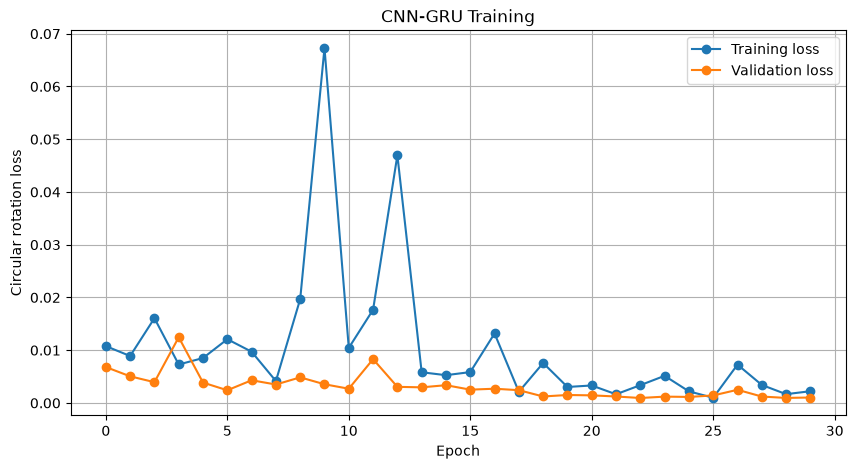

In [126]:
plt.figure(figsize=(10, 5))

plt.plot(
    train_losses,
    marker="o",
    label="Training loss"
)

plt.plot(
    val_losses,
    marker="o",
    label="Validation loss"
)

plt.xlabel("Epoch")
plt.ylabel("Circular rotation loss")
plt.title("CNN-GRU Training")
plt.legend()
plt.grid(True)

plt.show()

In [127]:
checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()

RotationCNNGRU(
  (encoder): Sequential(
    (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (4): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1

In [128]:
val_loss, predictions, true_angles = run_video(
    dataset=val_dataset,
    model=model,
    device=device,
    optimizer=None,
    chunk_size=chunk_size
)

# Convert network outputs into degrees
predicted_angles = np.rad2deg(
    np.arctan2(
        predictions[:, 1],
        predictions[:, 0]
    )
)

# Wrap ground truth to [-180, 180)
true_wrapped = (true_angles + 180) % 360 - 180

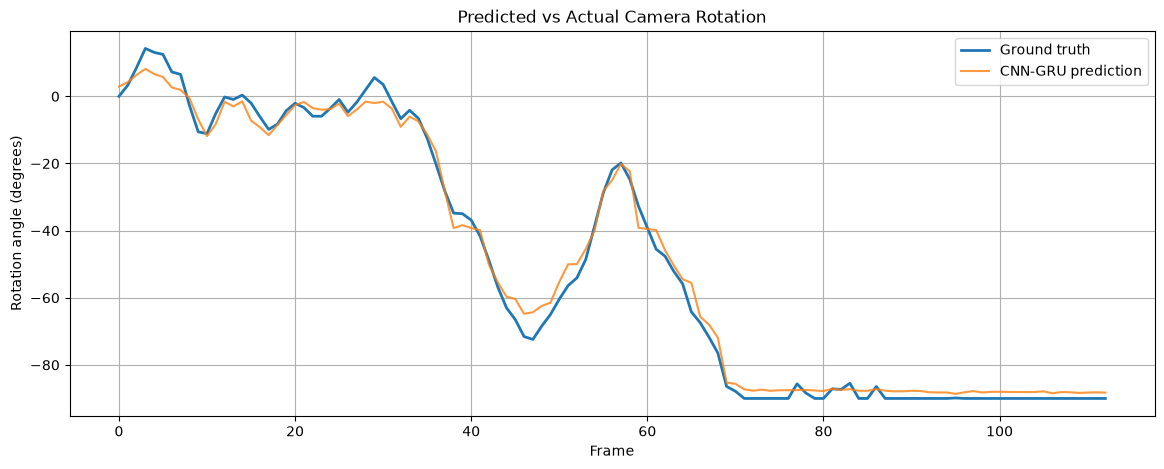

In [129]:
plt.figure(figsize=(14, 5))

plt.plot(
    true_wrapped,
    label="Ground truth",
    linewidth=2
)

plt.plot(
    predicted_angles,
    label="CNN-GRU prediction",
    alpha=0.8
)

plt.xlabel("Frame")
plt.ylabel("Rotation angle (degrees)")
plt.title("Predicted vs Actual Camera Rotation")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
# Circular error
errors = (predicted_angles - true_angles + 180) % 360 - 180

mae = np.mean(np.abs(errors))

In [130]:
rmse = np.sqrt(np.mean(errors**2))

# Baseline: always predict zero rotation
baseline_errors = (-true_angles + 180) % 360 - 180
baseline_mae = np.mean(np.abs(baseline_errors))

print(f"ResNet18-GRU MAE:  {mae:.2f}°")
print(f"ResNet18-GRU RMSE: {rmse:.2f}°")
print(f"Baseline MAE:      {baseline_mae:.2f}°")

ResNet18-GRU MAE:  2.60°
ResNet18-GRU RMSE: 3.17°
Baseline MAE:      50.86°


In [131]:
history = pd.DataFrame({
    "epoch": range(num_epochs),
    "train_loss": train_losses,
    "val_loss": val_losses,
    "train_dataset_id": train_dataset.dataset_id,
    "val_dataset_id": val_dataset.dataset_id
})

history.to_csv(
    train_dataset.log_dir / "cnn_gru_training_history.csv",
    index=False
)

print("Training history saved!")

Training history saved!
